# 05a-camera — Camera và cuộn thép trong đặc trưng

**Câu hỏi**: tín hiệu camera và cuộn thép nằm ở đâu trong đặc trưng, và lớn cỡ nào so với tín hiệu lớp khi đã tách phần hai thứ trùng nhau, trong không gian PCA-64 mà 06–14 dùng và trong đặc trưng thô mà 09 dùng? (Q05.03, QD25)

**Vị trí**: phân tích, không đổi kết quả của bước nào; sau 05 trong thứ tự chạy; dựa trên `05-pca`.

### Nguồn gốc (provenance)

In commit và trạng thái dirty của code, rồi đặt `XLA_FLAGS` trước mọi lần import jax (mẫu ở `lab/README.vi.md` §11).

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit d45007b | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `d45007b`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Dữ liệu

### 1.1 Gắn mỗi hàng của ảnh chụp với ảnh của nó

Mỗi hàng của `s0_x` và `pool_x` trong ảnh chụp 04 của `gc10_v2_ft_r0_s4` được gắn với ảnh gốc, để biết camera, cuộn thép (coil) và lớp của nó. Bước 04 xáo thứ tự hàng, nên không gắn được theo vị trí.

**Cách làm**:
- So từng hàng với file đặc trưng train theo byte, như `04-loader` §3.2. Hàng i của file là ảnh i trong `data_io.images` (`00-data-gc10` §1.6).
- Kiểm: lớp tra được phải trùng nhãn trong ảnh chụp; S0 chỉ gồm vai trò S0 (764 ảnh); pool gồm 698 ảnh vai trò S1 và 50 ảnh reserve.
- In bảng lớp × camera cho S0 và cho 698 ảnh lớp mới của pool. Đây là hai tập mà 2.1–3.1 phân tách phương sai.
- In thêm số cuộn và số cuộn của silk_spot được nhiều camera chụp. Nếu cuộn nằm gọn trong một camera thì ở 3.1 không tách được hiệu ứng cuộn khỏi camera.

In [2]:
# cell 1: inputs (r0 s4): rows of S0 and of the pool mapped to their images (camera, coil, class, role) by their bytes in the
#         train feature file; class x camera tables of S0 (764) and of the novel part of the pool (698)
import pickle
import numpy as np
import pandas as pd
import data_io
RUN = "gc10_v2_ft_r0_s4"
run_dir_11 = next(Path("runs").glob(f"*__{RUN}"))
b4_11, b5_11 = (pickle.loads((run_dir_11 / "snap" / f"{k}.pkl").read_bytes()) for k in ("04", "05"))
args_11 = b4_11["meta"]["args"]
F_11 = Path(args_11["data_dir"]) / args_11["pretrained_model_name"]
X_11 = np.load(F_11 / f"features-{F_11.name}.npy")                    # train feature file: row i = image i
pos_11 = {r.tobytes(): i for i, r in enumerate(X_11)}
assert len(pos_11) == len(X_11), "two byte-identical train rows"
img_11 = data_io.images("gc10")
tr_11 = img_11[img_11["part"] == "train"].set_index("row").sort_index()

def meta_11(A):                                                         # snapshot rows -> their images, in snapshot order
    return tr_11.loc[[pos_11[r.tobytes()] for r in np.asarray(A)]].reset_index()

s0_11, pool_11 = meta_11(b4_11["out"]["s0_x"]), meta_11(b4_11["out"]["pool_x"])
print("run", run_dir_11.name, "| features", F_11, "| sha256", replay._sha_file(F_11 / f"features-{F_11.name}.npy"))
print("labels agree (S0, pool):", np.array_equal(s0_11["cls"], np.asarray(b4_11["out"]["s0_y"]).astype(int)),
      np.array_equal(pool_11["cls"], np.asarray(b4_11["out"]["true_pool_y"]).astype(int)))
print("roles S0:", s0_11["role"].value_counts().to_dict(), "| roles pool:", pool_11["role"].value_counts().to_dict())
print("z shapes (s0, pool):", b5_11["out"]["z_s0"].shape, b5_11["out"]["z_pool"].shape)
nov_11 = (pool_11["cls"] >= 5).to_numpy()
for title_11, df_11 in (("S0 (764)", s0_11), ("novel part of the pool (698)", pool_11[nov_11])):
    t_11 = pd.crosstab(df_11["name"], df_11["cam"])
    t_11["n"] = t_11.sum(axis=1)
    print(f"\n{title_11}: class x camera\n{t_11.to_string()}")
silk_11 = pool_11[nov_11 & (pool_11["name"] == "silk_spot").to_numpy()]
print("\ncoils: S0", s0_11["coil"].nunique(), "| novel pool", pool_11[nov_11]["coil"].nunique(),
      "| silk_spot", silk_11["coil"].nunique(), "| silk_spot coils seen by > 1 camera",
      int((silk_11.groupby("coil")["cam"].nunique() > 1).sum()),
      "| largest silk_spot coil", int(silk_11["coil"].value_counts().iloc[0]))

run 20261020_084658__gc10_v2_ft_r0_s4 | features features/20261005_013115__gc10_ft_cls5first_img80pct_r0/dino-vitb16-sl | sha256 e90fe14a7920a7be
labels agree (S0, pool): True True
roles S0: {'S0': 764} | roles pool: {'S1': 698, 'reserve': 50}
z shapes (s0, pool): (764, 64) (748, 64)

S0 (764): class x camera
cam            01  02  03  04  05  06  07  08    n
name                                              
crescent_gap   38   3   1  25  35   2   2  37  143
oil_spot        3  21  22  18   0   4  42  20  130
punching_hole   0  12  57   0   0  68   0   0  137
water_spot     48  60  60   8   1   1   2   4  184
welding_line   13  43  27  16   6  25  30  10  170

novel part of the pool (698): class x camera
cam             01  02  03  04  05  06  07  08    n
name                                               
crease           5   7   3   3   2   5   5   2   32
inclusion        2  17  32  12   9  27  17  19  135
rolled_pit       0   6   8   1   0   1   1   0   17
silk_spot      131  26  42

- **Kết quả**:
  - Run `20261020_084658__gc10_v2_ft_r0_s4`, đặc trưng `features/20261005_013115__gc10_ft_cls5first_img80pct_r0/dino-vitb16-sl` (sha256 `e90fe14a7920a7be`).
  - Lớp tra từ ảnh trùng nhãn trong ảnh chụp ở cả S0 và pool (True, True). S0 gồm đúng 764 ảnh vai trò S0; pool gồm 698 ảnh vai trò S1 và 50 ảnh reserve.
  - S0, lớp × camera: punching_hole chỉ từ camera 02, 03, 06; water_spot có 168/184 ảnh từ 01–03; crescent_gap có 97/143 ảnh từ ba camera tối 04, 05, 08 (tự cộng); welding_line và oil_spot trải 7–8 camera.
  - 698 ảnh lớp mới của pool: waist_folding có 84/94 ảnh từ 06–07; rolled_pit có 14/17 từ 02–03; silk_spot trải 8 camera, nhiều nhất camera 01 (131/420); crease (32 ảnh) và inclusion (135 ảnh) trải đều.
  - Cuộn thép: S0 có 271 cuộn, phần lớp mới của pool có 99. silk_spot nằm trong 16 cuộn; cuộn lớn nhất có 155/420 ảnh (37%); 9/16 cuộn được nhiều hơn một camera chụp.
- **Ý nghĩa**:
  - Gắn hàng theo byte là đúng; các cell sau dùng bảng này.
  - Ở S0, camera và lớp trùng nhau một phần: punching_hole và water_spot gần như nằm gọn trong vài camera. Phần phương sai của hai lớp này không chia được rạch ròi cho lớp hay camera, nên 2.1 phải báo phần chung riêng.
  - Ở lớp mới, waist_folding và rolled_pit gắn với camera, còn crease, inclusion, silk_spot thì không. [SUY LUẬN] Nếu camera mang nhiều phương sai, ảnh crease sẽ bị kéo về nhiều hướng theo camera, còn waist_folding tụ lại một phần nhờ camera.
  - Cuộn thép không nằm gọn trong camera (9/16 cuộn silk_spot có nhiều camera), nên 3.1 tách được một phần hiệu ứng cuộn khỏi camera. Một cuộn chiếm 37% silk_spot: đây là ứng viên giải thích vì sao silk_spot chiếm 2–3 cụm.

## 2. Không gian PCA-64 (dùng ở 06–14)

### 2.1 S0: phần do lớp, phần do camera, phần chung

Hỏi: trong 64 thành phần mà các Gaussian ở 06 học trên đó, bao nhiêu phương sai của S0 đi theo lớp, bao nhiêu đi theo camera, khi hai yếu tố trùng nhau một phần (1.1)?

**Cách làm**: phân tách phương sai (variation partitioning; Borcard, Legendre & Drapeau 1992). Hồi quy đặc trưng Y (764 × 64) theo biến giả (dummy) của lớp, của camera, và của cả hai trong một mô hình cộng (không có tương tác). Gọi R²_L, R²_C, R²_LC là ba hệ số xác định (coefficient of determination). Khi đó:
- [a] chỉ do lớp = R²_LC − R²_C;
- [c] chỉ do camera = R²_LC − R²_L;
- [b] phần chung = R²_L + R²_C − R²_LC, tức phần không chia được cho riêng yếu tố nào vì hai yếu tố đi cùng nhau;
- [d] phần dư = 1 − R²_LC.

Mỗi R² được hiệu chỉnh theo số biến giả, R²_adj = 1 − (1 − R²)(n − 1)/(n − p − 1) (Ezekiel 1930), như Peres-Neto et al. (2006) khuyên dùng cho phép phân tách này. "Cả 64 chiều" cộng tổng bình phương qua mọi cột, nên mỗi thành phần nặng theo phương sai của nó.

Ví dụ tính tay (chưa hiệu chỉnh), 4 ảnh, một chiều đặc trưng y = [1, 3, 5, 7]; lớp A, A, B, B; camera P, Q, P, Q:
1. Trung bình 4, tổng bình phương 9 + 1 + 1 + 9 = 20.
2. Theo lớp: trung bình A = 2, B = 6; phần dư (−1, 1, −1, 1), tổng 4, nên R²_L = 16/20 = 0.8.
3. Theo camera: trung bình P = 3, Q = 5; phần dư (−2, −2, 2, 2), tổng 16, nên R²_C = 4/20 = 0.2.
4. Cả hai: y = 1 + 4·[B] + 2·[Q] khớp đúng cả 4 ảnh, nên R²_LC = 1.
5. [a] = 1 − 0.2 = 0.8; [c] = 1 − 0.8 = 0.2; [b] = 0.8 + 0.2 − 1 = 0; [d] = 0. Thiết kế cân (mỗi lớp có đủ hai camera) nên phần chung bằng 0. Nếu lớp A chỉ từ camera P thì phần chung > 0.

Cell kiểm hàm trên chính ví dụ này (không hiệu chỉnh), rồi tính cho S0: cả 64 chiều, và từng thành phần trong 16 thành phần đầu.

Dự đoán [SUY LUẬN]: [a] lớn ở các thành phần đầu, vì PCA fit trên S0 và đặc trưng fine-tune bằng chính nhãn này; [c] nhỏ (dưới 0.1) nhưng [b] khác 0 vì punching_hole, water_spot gần như gắn với camera; [d] lớn nhất trên cả 64 chiều.

hand example (not adjusted): {'cls': np.float64(0.8), 'shared': np.float64(0.0), 'cam': np.float64(0.2), 'resid': np.float64(0.0)}
S0, all 64 components: {'cls': np.float64(0.304), 'shared': np.float64(0.145), 'cam': np.float64(0.07), 'resid': np.float64(0.481)}
      var_share    cls  shared    cam  resid
pc1       0.249  0.681   0.188  0.031  0.101
pc2       0.189  0.339   0.456  0.078  0.127
pc3       0.076  0.510   0.148  0.010  0.331
pc4       0.053  0.348   0.094  0.159  0.400
pc5       0.038  0.210  -0.016  0.338  0.467
pc6       0.031  0.035  -0.013  0.068  0.910
pc7       0.023  0.014   0.009  0.054  0.922
pc8       0.021  0.019  -0.021  0.192  0.810
pc9       0.019  0.022  -0.009  0.043  0.944
pc10      0.018  0.008  -0.006  0.058  0.940
pc11      0.015  0.014  -0.001  0.051  0.937
pc12      0.014  0.008  -0.002  0.149  0.845
pc13      0.012  0.012  -0.001  0.022  0.968
pc14      0.012  0.007  -0.001  0.060  0.935
pc15      0.012  0.044  -0.017  0.036  0.937
pc16      0.011  

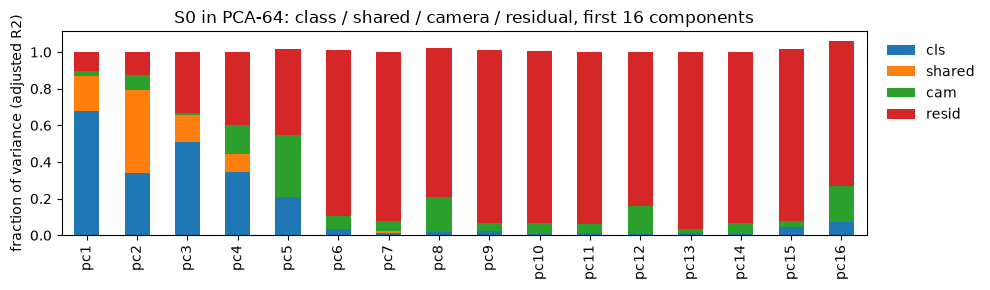

In [3]:
# cell 2: S0 in PCA-64: variation partitioning of class and camera (additive model, adjusted R2), over all 64 components
#         (variance-weighted) and per component for the first 16; the function is checked on the hand example first
import matplotlib.pyplot as plt

def r2_21(Y, factors, adjust=True):
    """R2 of Y (n x k) on the dummies of the factors: (all columns together, per column)."""
    Y = np.asarray(Y, np.float64)
    Y = Y - Y.mean(0)
    D = np.hstack([np.ones((len(Y), 1))] + [pd.get_dummies(pd.Series(np.asarray(f)), drop_first=True).to_numpy(float)
                                           for f in factors])
    B, *_ = np.linalg.lstsq(D, Y, rcond=None)
    ss_res, ss_tot = ((Y - D @ B) ** 2).sum(0), (Y ** 2).sum(0)
    n, p = len(Y), np.linalg.matrix_rank(D) - 1                       # p: dummies, intercept excluded
    fix = (lambda r: 1 - (1 - r) * (n - 1) / (n - p - 1)) if adjust else (lambda r: r)
    return fix(1 - ss_res.sum() / ss_tot.sum()), fix(1 - ss_res / ss_tot)

def parts_21(Y, lab, cam, adjust=True):
    """Fractions [a] class only, [b] shared, [c] camera only, [d] residual: (all columns together, per column)."""
    (L, l), (C, c), (LC, lc) = (r2_21(Y, f, adjust) for f in ((lab,), (cam,), (lab, cam)))
    whole = dict(cls=LC - C, shared=L + C - LC, cam=LC - L, resid=1 - LC)
    per = pd.DataFrame(dict(cls=lc - c, shared=l + c - lc, cam=lc - l, resid=1 - lc))
    return whole, per

toy_21, _ = parts_21(np.array([[1.], [3.], [5.], [7.]]), list("AABB"), list("PQPQ"), adjust=False)
print("hand example (not adjusted):", {k: round(v, 3) for k, v in toy_21.items()})

Z_21 = b5_11["out"]["z_s0"]
whole_21, per_21 = parts_21(Z_21, s0_11["name"], s0_11["cam"])
per_21.insert(0, "var_share", Z_21.var(0) / Z_21.var(0).sum())
per_21.index = [f"pc{i + 1}" for i in range(len(per_21))]
print("S0, all 64 components:", {k: round(v, 3) for k, v in whole_21.items()})
print(per_21.head(16).round(3).to_string())
print("components where camera only > class only:", int((per_21["cam"] > per_21["cls"]).sum()), "of 64; their variance share",
      round(float(per_21.loc[per_21["cam"] > per_21["cls"], "var_share"].sum()), 3))

ax_21 = per_21.head(16)[["cls", "shared", "cam", "resid"]].clip(lower=0).plot.bar(stacked=True, figsize=(10, 3))
ax_21.set_ylabel("fraction of variance (adjusted R2)")
ax_21.set_title("S0 in PCA-64: class / shared / camera / residual, first 16 components")
ax_21.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)   # outside the axes, right of the bars
plt.tight_layout()
plt.show()

- **Kết quả**:
  - Ví dụ tính tay (không hiệu chỉnh): lớp 0.8, chung 0.0, camera 0.2, dư 0.0, đúng như tính tay. Hàm đúng.
  - S0, cả 64 thành phần (R² hiệu chỉnh): chỉ do lớp 0.304, chung 0.145, chỉ do camera 0.070, dư 0.481. Như vậy lớp giải thích 0.449 và camera 0.215 nếu tính cả phần chung (tự cộng).
  - Theo từng thành phần:
    - pc1–pc4 (57% phương sai) do lớp chi phối: lớp 0.34–0.68. pc2 có phần chung lớn nhất (0.456).
    - pc5 do camera nhiều hơn lớp (0.338 so với 0.210).
    - Từ pc6, phần dư chiếm 0.79–0.97. Camera vượt lớp ở pc8 (0.192), pc12 (0.149), pc16 (0.195).
  - Camera vượt lớp ở 56/64 thành phần, chiếm 0.412 tổng phương sai S0.
  - Vài phần chung âm (tới −0.060 ở pc16).
- **Ý nghĩa**:
  - Dự đoán đúng cả bốn ý: lớp chiếm các thành phần đầu, camera riêng nhỏ (0.070 < 0.1), phần chung khác 0, phần dư lớn nhất. Phần chung 0.145 gấp đôi phần riêng của camera: ở S0, phần lớn tín hiệu camera không tách được khỏi lớp, vì punching_hole và water_spot gắn với vài camera (1.1).
  - Không gian của 06–14 có hai tầng:
    - 4 thành phần đầu mang lớp;
    - 60 thành phần còn lại là độ trải trong lớp, và phần giải thích được của chúng nghiêng về camera (56/64 thành phần).
  - [SUY LUẬN] Gaussian Σ_c học ở 06 sống trên cả 64 chiều, nên phần ngoài 4 thành phần đầu mô hình hoá một phần là camera. Ở 08, khi tách số hạng bậc hai, cần xem các hướng riêng lớn của E_c nằm ở pc1–pc4 (lớp) hay ở pc5, pc8, pc12, pc16 (camera).
  - Phần chung âm là bình thường khi hai yếu tố triệt tiêu nhau một phần (suppression; Legendre & Legendre 2012, §10.3). Các giá trị ở đây nhỏ, coi như 0.

### 2.2 Lớp mới trong PCA-64, và camera bên trong từng lớp

Hỏi hai điều:
1. Với 698 ảnh lớp mới của pool, chiếu vào không gian của S0, các phần lớp / chung / camera / dư ra sao?
2. Bên trong mỗi lớp, camera giải thích bao nhiêu phương sai? Đây là độ trải mà Gaussian của lớp đó phải ôm: Σ_c ở 06 với lớp cũ, ở 11 và 13 với lớp mới.

**Cách làm**:
- Hàm của 2.1 trên `z_pool` (chỉ 698 ảnh lớp mới, không có ảnh cũ; QD24), với 5 lớp mới.
- Trong từng lớp: R² hiệu chỉnh của camera trên ảnh của riêng lớp đó (lớp cũ trên S0, lớp mới trên pool). Lớp ít ảnh (rolled_pit 17 ảnh, 6 camera) có hiệu chỉnh lớn, nên số của nó kém tin cậy.

Dự đoán [SUY LUẬN]:
- phần lớp nhỏ hơn S0, vì PCA không fit trên lớp mới (`05-pca` §4.1: chỉ giữ 0.53–0.69 phương sai trong lớp);
- camera trong lớp cao ở silk_spot, inclusion, crease (trải nhiều camera), thấp ở waist_folding, rolled_pit (dồn vài camera), và ở punching_hole, water_spot.

In [4]:
# cell 3: the 698 novel pool images in PCA-64: class / shared / camera / residual over all 64 components (5 novel classes);
#         within each class (old classes on S0, novel classes on the pool): share of its variance explained by camera
Zn_22 = b5_11["out"]["z_pool"][nov_11]
pn_22 = pool_11[nov_11].reset_index(drop=True)                        # row i of pn_22 = row i of Zn_22
whole_22, per_22 = parts_21(Zn_22, pn_22["name"], pn_22["cam"])
print("novel pool (698), all 64 components:", {k: round(float(v), 3) for k, v in whole_22.items()})
var_22 = Zn_22.var(0) / Zn_22.var(0).sum()
print("first 5 components, share of the novel pool variance:", var_22[:5].round(3).tolist())
print(per_22.head(5).round(3).set_axis([f"pc{i + 1}" for i in range(5)]).to_string())
rows_22 = []
for set_22, Z, df in (("S0", Z_21, s0_11), ("pool novel", Zn_22, pn_22)):
    for name_22 in sorted(df["name"].unique()):
        m = (df["name"] == name_22).to_numpy()
        cams = df.loc[m, "cam"].to_numpy()
        r2 = r2_21(Z[m], (cams,))[0] if len(set(cams)) > 1 else float("nan")
        rows_22.append(dict(set=set_22, cls=name_22, n=int(m.sum()), cameras=len(set(cams)), camera_r2_adj=round(float(r2), 3)))
print("\nwithin each class: variance explained by camera (adjusted R2, all 64 components)")
print(pd.DataFrame(rows_22).to_string(index=False))

novel pool (698), all 64 components: {'cls': 0.187, 'shared': 0.086, 'cam': 0.232, 'resid': 0.495}
first 5 components, share of the novel pool variance: [0.13300000131130219, 0.041999999433755875, 0.017000000923871994, 0.04500000178813934, 0.07999999821186066]
       cls  shared    cam  resid
pc1  0.471   0.200  0.079  0.250
pc2  0.105   0.134  0.400  0.361
pc3  0.151   0.028  0.070  0.752
pc4  0.072  -0.028  0.561  0.395
pc5  0.030   0.097  0.705  0.168

within each class: variance explained by camera (adjusted R2, all 64 components)
       set           cls   n  cameras  camera_r2_adj
        S0  crescent_gap 143        8          0.116
        S0      oil_spot 130        7          0.317
        S0 punching_hole 137        3          0.102
        S0    water_spot 184        8          0.223
        S0  welding_line 170        8          0.237
pool novel        crease  32        8          0.129
pool novel     inclusion 135        8          0.425
pool novel    rolled_pit  17       

- **Kết quả**:
  - 698 ảnh lớp mới, cả 64 thành phần (R² hiệu chỉnh): chỉ do lớp 0.187, chung 0.086, chỉ do camera 0.232, dư 0.495. Lớp giải thích 0.273 và camera 0.318 khi tính cả phần chung (tự cộng).
  - Theo thành phần: pc1 (13.3% phương sai lớp mới) do lớp chi phối (0.471). pc2, pc4, pc5 do camera chi phối (0.400, 0.561, 0.705); ba thành phần này mang 16.7% phương sai lớp mới (tự cộng).
  - Phần camera giải thích bên trong từng lớp:
    - lớp cũ trên S0: punching_hole 0.102, crescent_gap 0.116, water_spot 0.223, welding_line 0.237, oil_spot 0.317;
    - lớp mới trên pool: silk_spot 0.507, inclusion 0.425, rolled_pit 0.157, crease 0.129, waist_folding 0.128.
- **Ý nghĩa**:
  - Với lớp mới, trong không gian của S0, camera giải thích nhiều phương sai hơn lớp (0.318 so với 0.273). Ở S0 thì ngược lại (camera 0.215, lớp 0.449). PCA được fit để giữ hướng phân biệt lớp cũ, nên với lớp mới, phần còn lại nghiêng về camera.
  - Dự đoán đúng ở ba điểm: lớp mới có phần lớp nhỏ hơn S0; silk_spot và inclusion có camera cao; waist_folding và punching_hole thấp. Sai ở hai điểm: crease thấp (0.129) dù trải 8 camera, và water_spot không thấp (0.223).
  - [SUY LUẬN] crease chỉ có 32 ảnh cho 8 camera, nên phép hiệu chỉnh R² trừ mạnh; số của crease và rolled_pit kém tin cậy.
  - Một nửa phương sai trong lớp của silk_spot (0.507) và 0.425 của inclusion đi theo camera. Gaussian của hai lớp này ở 11, 13 vì vậy phải ôm một hỗn hợp theo camera, không phải một đám mây đơn.
  - [SUY LUẬN] Nếu đặc trưng thô cũng vậy, silk_spot chiếm 2–3 cụm ở K = 5 có thể là chia theo camera; 3.1 kiểm phần này trong đúng không gian của k-means.

## 3. Đặc trưng thô 768 chiều (dùng ở 09)

### 3.1 Lớp mới: lớp, camera, và cuộn thép trong silk_spot

k-means ở 09 cực tiểu tổng bình phương khoảng cách Euclid trên đặc trưng thô. Phần phương sai do camera (hay do cuộn) trong không gian này vì vậy là phần mà k-means có thể "được thưởng" khi chia theo camera thay vì theo lớp.

**Cách làm**: hàm của 2.1 trên `pool_x` thô của 698 ảnh lớp mới:
- cả 768 chiều, với lớp và camera;
- trong từng lớp, phần do camera, để so với PCA-64 (2.2);
- riêng silk_spot (420 ảnh), phân tách cuộn thép (16 cuộn) và camera; cột "cls" của hàm lúc này là "chỉ do cuộn". 9/16 cuộn silk_spot có nhiều camera (1.1), nên hai yếu tố tách được một phần.

Dự đoán [SUY LUẬN]:
- camera ở đặc trưng thô ít nhất cũng lớn như trong PCA-64, vì PCA-64 bỏ đi một phần phương sai của lớp mới (`05-pca` §3.1);
- trong silk_spot, cuộn giải thích nhiều hơn camera, vì một cuộn chiếm 37% số ảnh.

In [5]:
# cell 4: raw 768-d features (the k-means space of step 09), 698 novel pool images: class / shared / camera / residual;
#         within each novel class, the share explained by camera (raw vs PCA-64); inside silk_spot, coil vs camera
Xn_31 = np.asarray(b4_11["out"]["pool_x"])[nov_11]
whole_31, _ = parts_21(Xn_31, pn_22["name"], pn_22["cam"])
print("novel pool (698), raw 768-d:", {k: round(float(v), 3) for k, v in whole_31.items()})
pca_cam_31 = {r["cls"]: r["camera_r2_adj"] for r in rows_22 if r["set"] == "pool novel"}
rows_31 = []
for name_31 in sorted(pn_22["name"].unique()):
    m = (pn_22["name"] == name_31).to_numpy()
    rows_31.append(dict(cls=name_31, n=int(m.sum()), camera_raw=round(float(r2_21(Xn_31[m], (pn_22.loc[m, "cam"].to_numpy(),))[0]), 3),
                        camera_pca64=pca_cam_31[name_31]))
print("\nwithin each novel class: variance explained by camera (adjusted R2)")
print(pd.DataFrame(rows_31).to_string(index=False))
ms_31 = (pn_22["name"] == "silk_spot").to_numpy()
silk_parts_31, _ = parts_21(Xn_31[ms_31], pn_22.loc[ms_31, "coil"].to_numpy(), pn_22.loc[ms_31, "cam"].to_numpy())
print("\nsilk_spot (420), raw: coil only {cls:.3f}, shared {shared:.3f}, camera only {cam:.3f}, residual {resid:.3f}".format(**silk_parts_31))
print("silk_spot, coil alone:", round(float(r2_21(Xn_31[ms_31], (pn_22.loc[ms_31, "coil"].to_numpy(),))[0]), 3),
      "| camera alone:", round(float(r2_21(Xn_31[ms_31], (pn_22.loc[ms_31, "cam"].to_numpy(),))[0]), 3))

novel pool (698), raw 768-d: {'cls': 0.146, 'shared': 0.063, 'cam': 0.198, 'resid': 0.593}

within each novel class: variance explained by camera (adjusted R2)
          cls   n  camera_raw  camera_pca64
       crease  32       0.084         0.129
    inclusion 135       0.353         0.425
   rolled_pit  17       0.079         0.157
    silk_spot 420       0.431         0.507
waist_folding  94       0.111         0.128

silk_spot (420), raw: coil only 0.176, shared 0.221, camera only 0.210, residual 0.393
silk_spot, coil alone: 0.397 | camera alone: 0.431


- **Kết quả**:
  - 698 ảnh lớp mới, đặc trưng thô 768 chiều (R² hiệu chỉnh): chỉ do lớp 0.146, chung 0.063, chỉ do camera 0.198, dư 0.593. Lớp giải thích 0.209, camera 0.261 khi tính cả phần chung (tự cộng).
  - Camera trong từng lớp, đặc trưng thô so với PCA-64:
    - silk_spot 0.431 so với 0.507;
    - inclusion 0.353 so với 0.425;
    - rolled_pit 0.079 so với 0.157;
    - waist_folding 0.111 so với 0.128;
    - crease 0.084 so với 0.129.
  - silk_spot (420 ảnh), đặc trưng thô:
    - phân tách: chỉ do cuộn 0.176, chung 0.221, chỉ do camera 0.210, dư 0.393;
    - riêng từng yếu tố: cuộn 0.397, camera 0.431.
- **Ý nghĩa**:
  - Dự đoán thứ nhất sai: trong đặc trưng thô, camera giải thích ít phương sai hơn trong PCA-64 (0.261 so với 0.318). Nhưng lớp cũng giảm theo (0.209 so với 0.273), vì đặc trưng thô có nhiều phương sai dư hơn (0.593 so với 0.495). Tỉ số camera/lớp gần như giữ nguyên: 1.25 ở đặc trưng thô, 1.16 ở PCA-64 (tự chia). Kết luận của 2.2 vì thế giữ trong không gian của k-means: với lớp mới, camera mang nhiều phương sai hơn lớp.
  - Dự đoán thứ hai sai: trong silk_spot, cuộn không vượt camera (0.397 so với 0.431). Mỗi yếu tố có một phần riêng cỡ 0.18–0.21, và hai yếu tố cùng giải thích 0.607 phương sai của silk_spot (tự cộng).
  - [SUY LUẬN] Hàm mục tiêu của k-means là tổng bình phương trong cụm, nên một phân hoạch chia silk_spot theo camera hay cuộn sẽ giảm hàm mục tiêu nhiều. Đây là một giải thích ứng viên cho việc silk_spot chiếm 2–3 cụm ở K = 5 (QD24). Phương sai lớn chưa chắc tạo thành cụm tách rời. 09 sẽ kiểm trực tiếp bằng bảng cụm × camera và cụm × cuộn, vốn không cần nhãn.
  - Ngược lại, crease, rolled_pit, waist_folding có rất ít phương sai theo camera (0.08–0.11). [SUY LUẬN] Ba lớp này bị gộp ở K = 5 (`05-pca` §4.1) không phải vì camera làm chúng tản ra, mà vì chúng không được dành cụm.

## 4. Qua 15 ảnh chụp và `fz`

### 4.1 Các phần có giữ qua FT seed không; fine-tune đổi tín hiệu camera thế nào

Trong một FT seed, 5 seed dùng cùng ảnh và cùng đặc trưng. Chỉ PCA khác nhau, và chỉ ở 3–4 hướng cuối (`05-pca` §5.1). Vì vậy:
- các phần trong PCA-64 tính cho cả 15 ảnh chụp, mỗi ảnh chụp dùng PCA của chính nó;
- các phần ở đặc trưng thô chỉ tính một lần cho mỗi bộ đặc trưng (r0, r1, r2), vì 698 ảnh lớp mới và đặc trưng của chúng giống nhau ở mọi seed;
- `fz` (DINO đóng băng, token CLS) là bối cảnh phụ (QD19), chỉ có đặc trưng thô vì không có ảnh chụp.

**Cách làm**: như 1.1, 2.1, 2.2, 3.1. Với `fz`, các hàng vai trò S1 lấy theo thứ tự file, sau khi kiểm nhãn của file trùng `data_io`.

Dự đoán [SUY LUẬN]:
- trong một FT seed, các phần lệch nhau dưới 0.01;
- giữa các FT seed lệch ít;
- `fz` có phần camera lớn hơn và phần lớp nhỏ hơn `ft`, vì fine-tune học từ nhãn lớp. Nhưng nhãn của S0 cũng gắn với camera (1.1), nên fine-tune có thể học cả camera; dự đoán này vì vậy không chắc.

In [6]:
# cell 5: across the 15 snapshots (pickle) and fz: S0 and novel pool in PCA-64 (each snapshot's own PCA); novel pool raw 768-d
#         once per feature set (the same 698 images and features at every seed); fz raw as context (QD19)
rows_41, pos_41 = [], {}
for d in sorted(Path("runs").glob("*__gc10_v2_ft_r[0-2]_s[0-4]")):
    tag_41 = d.name.split("__")[1][len("gc10_v2_ft_"):]
    b4, b5 = (pickle.loads((d / "snap" / f"{k}.pkl").read_bytes()) for k in ("04", "05"))
    F = Path(b4["meta"]["args"]["data_dir"]) / b4["meta"]["args"]["pretrained_model_name"]
    if F not in pos_41:
        pos_41[F] = {r.tobytes(): i for i, r in enumerate(np.load(F / f"features-{F.name}.npy"))}
    s0 = tr_11.loc[[pos_41[F][r.tobytes()] for r in np.asarray(b4["out"]["s0_x"])]].reset_index()
    pool = tr_11.loc[[pos_41[F][r.tobytes()] for r in np.asarray(b4["out"]["pool_x"])]].reset_index()
    nov = (pool["cls"] >= 5).to_numpy()
    w0, _ = parts_21(b5["out"]["z_s0"], s0["name"], s0["cam"])
    wn, _ = parts_21(b5["out"]["z_pool"][nov], pool.loc[nov, "name"], pool.loc[nov, "cam"])
    rows_41.append(dict(snap=tag_41, **{f"S0_{k}": round(float(v), 3) for k, v in w0.items()},
                        **{f"nov_{k}": round(float(v), 3) for k, v in wn.items()}))
print("PCA-64, each snapshot (S0: 5 old classes; nov: 698 novel pool images)")
print(pd.DataFrame(rows_41).to_string(index=False))

s1_rows_41 = tr_11.index[tr_11["role"] == "S1"].to_numpy()             # the 698 novel images, file order
nov_meta_41 = tr_11.loc[s1_rows_41].reset_index()
silk_41 = (nov_meta_41["name"] == "silk_spot").to_numpy()
sets_41 = {f"ft r{r}": next(Path("features").glob(f"*__gc10_ft_cls5first_img80pct_r{r}")) / "dino-vitb16-sl" for r in range(3)}
sets_41["fz"] = next(Path("features").glob("*__gc10_fz_cls5first_img80pct")) / "dino-vitb16"
raw_41 = []
for name_41, F in sets_41.items():
    X = np.load(F / f"features-{F.name}.npy")
    assert np.array_equal(np.load(F / f"labels-{F.name}.npy").astype(int)[s1_rows_41], nov_meta_41["cls"]), name_41
    Xs = X[s1_rows_41]
    w, _ = parts_21(Xs, nov_meta_41["name"], nov_meta_41["cam"])
    raw_41.append(dict(features=name_41, **{k: round(float(v), 3) for k, v in w.items()},
                       silk_camera=round(float(r2_21(Xs[silk_41], (nov_meta_41.loc[silk_41, "cam"].to_numpy(),))[0]), 3),
                       silk_coil=round(float(r2_21(Xs[silk_41], (nov_meta_41.loc[silk_41, "coil"].to_numpy(),))[0]), 3)))
print("\nraw 768-d, 698 novel images (cls / shared / cam / resid), and inside silk_spot: camera alone, coil alone")
print(pd.DataFrame(raw_41).to_string(index=False))

PCA-64, each snapshot (S0: 5 old classes; nov: 698 novel pool images)
 snap  S0_cls  S0_shared  S0_cam  S0_resid  nov_cls  nov_shared  nov_cam  nov_resid
r0_s0   0.304      0.145   0.070     0.481    0.187       0.087    0.231      0.495
r0_s1   0.304      0.145   0.070     0.481    0.188       0.086    0.232      0.495
r0_s2   0.304      0.145   0.070     0.481    0.187       0.087    0.232      0.495
r0_s3   0.304      0.145   0.070     0.481    0.187       0.086    0.232      0.494
r0_s4   0.304      0.145   0.070     0.481    0.187       0.086    0.232      0.495
r1_s0   0.290      0.143   0.069     0.498    0.187       0.061    0.224      0.528
r1_s1   0.290      0.143   0.069     0.498    0.188       0.061    0.223      0.528
r1_s2   0.290      0.143   0.069     0.498    0.187       0.062    0.223      0.528
r1_s3   0.290      0.143   0.069     0.498    0.187       0.062    0.224      0.528
r1_s4   0.290      0.143   0.069     0.498    0.187       0.062    0.224      0.528
r2_s0 

- **Kết quả**:
  - Kiểm: hàng `r0_s4` trùng 2.1 và 2.2 (S0: 0.304, 0.145, 0.070, 0.481; lớp mới: 0.187, 0.086, 0.232, 0.495). Hàng `ft r0` trùng 3.1 (0.146, 0.063, 0.198, 0.593; trong silk_spot: camera 0.431, cuộn 0.397).
  - PCA-64, trong một FT seed: 5 seed lệch nhau tối đa 0.001 ở mọi phần.
  - PCA-64, giữa các FT seed:
    - S0: lớp 0.290–0.304, chung 0.143–0.145, camera 0.069–0.070;
    - lớp mới: lớp 0.182–0.188, chung 0.061–0.087, camera 0.223–0.235.
  - Đặc trưng thô, 698 ảnh lớp mới (lớp / chung / camera / dư):
    - `ft` r0–r2: lớp 0.140–0.146, chung 0.044–0.063, camera 0.190–0.198, dư 0.593–0.620;
    - `fz`: lớp 0.119, chung 0.064, camera 0.221, dư 0.597.
  - Trong silk_spot, camera / cuộn: `ft` 0.420–0.431 / 0.382–0.398; `fz` 0.437 / 0.437.
- **Ý nghĩa**:
  - Dự đoán đúng: trong một FT seed các phần gần như không đổi, vì PCA chỉ khác nhau ở vài hướng cuối, mang rất ít phương sai. Giữa các FT seed các phần cũng gần nhau.
  - Kết luận của 2.2 và 3.1 giữ ở cả 3 FT seed (đơn vị n = 3): với 698 ảnh lớp mới, phần chỉ do camera lớn hơn phần chỉ do lớp, ở cả PCA-64 (0.223–0.235 so với 0.182–0.188) và đặc trưng thô (0.190–0.198 so với 0.140–0.146).
  - Dự đoán về `fz` đúng hướng nhưng chênh lệch nhỏ: fine-tune nâng phần chỉ do lớp từ 0.119 lên 0.140–0.146 và hạ phần chỉ do camera từ 0.221 xuống 0.190–0.198. Trong silk_spot, cuộn giảm từ 0.437 xuống 0.382–0.398, còn camera gần như giữ nguyên.
  - [SUY LUẬN] Fine-tune trên 5 lớp cũ chỉ làm yếu tín hiệu camera một chút. Tín hiệu đó vẫn lớn hơn tín hiệu lớp ở lớp mới, nên đây là tính chất của đặc trưng DINO trên GC10, không do fine-tune tạo ra. E03.01 (trừ trung bình theo camera trên `fz`) vì thế đã đúng chỗ, nhưng chưa chứng minh được tác dụng vì k-means quá nhiễu (Q09.12).

## Summary (EN)

1. **In the S0 subspace, the leading components carry class, not camera.** Over the 64 PCA components of S0, variation partitioning (adjusted R², additive model) gives class only 0.304, shared 0.145, camera only 0.070, residual 0.481. pc1–pc4 (57% of the variance) are class-dominated; camera exceeds class in 56/64 components, which hold 41% of the variance (§2.1; run `gc10_v2_ft_r0_s4`). Camera and class overlap in S0, since punching_hole and water_spot come from few cameras (§1.1).
2. **For the novel classes, camera carries more variance than class, in both spaces.** On the 698 novel pool images, camera only exceeds class only in PCA-64 (0.223–0.235 vs 0.182–0.188) and in the raw 768-d features used by k-means (0.190–0.198 vs 0.140–0.146), in all three FT seeds (§2.2, §3.1, §4.1).
3. **silk_spot and inclusion spread by camera; the rare classes do not.** Camera explains 0.431 of silk_spot's raw within-class variance and 0.353 of inclusion's, but 0.08–0.11 for crease, rolled_pit and waist_folding. Inside silk_spot, coil and camera together explain 0.607 (coil only 0.176, shared 0.221, camera only 0.210) (§3.1). [inference] k-means can lower its objective by splitting silk_spot along camera or coil, a candidate cause of its 2–3 clusters at K = 5; checked with cluster × camera/coil tables in 09.
4. **Fine-tuning weakens the camera signal only slightly.** Frozen DINO (`fz`) gives class only 0.119 and camera only 0.221 on the novel images, against 0.140–0.146 and 0.190–0.198 for `ft` (§4.1). Within an FT seed the five seeds agree within 0.001 (§4.1).